## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [1]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# >>> EDIT ME: point this at YOUR actual file in Google Drive <<<
# Example: if you uploaded heart_disease.csv into "Colab Notebooks/lab04/"
DATA_PATH = "//content/drive/MyDrive/processed.cleveland.data"


## Cell 2 — Import Libraries

In [7]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [8]:
# Load the UCI Heart Disease dataset from DATA_PATH.
# The raw UCI file has NO header row and uses'?' for missing values

column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(DATA_PATH, header=None, names=column_names, na_values="?")

# If your CSV already came WITH a header row (e.g. a Kaggle export with
# columns already named), comment the line above and use this instead:
# df = pd.read_csv(DATA_PATH, na_values="?")

df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [9]:
print("Shape (rows, columns):", df.shape)

print("\nColumn names and dtypes:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

print("\nDescriptive statistics:")
display(df.describe(include="all"))

print("\nUnique values in target:", sorted(df["target"].unique()))


Shape (rows, columns): (303, 14)

Column names and dtypes:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000



Unique values in target: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Raw target class counts (0 = no disease, 1-4 = increasing severity):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Raw target class percentages:
target
0    54.13
1    18.15
2    11.88
3    11.55
4     4.29
Name: proportion, dtype: float64

Binarized class counts (0 = no disease, 1 = disease):
target
0    164
1    139
Name: count, dtype: int64

Binarized class percentages:
target
0    54.13
1    45.87
Name: count, dtype: float64


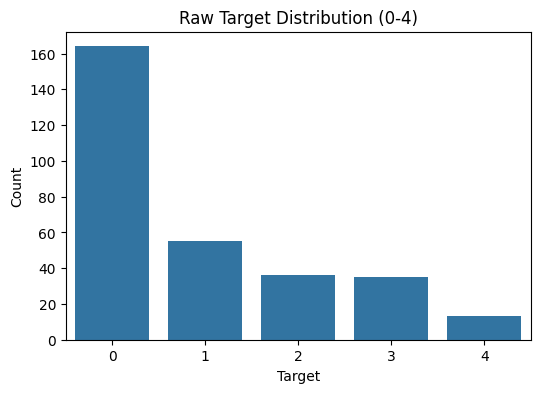

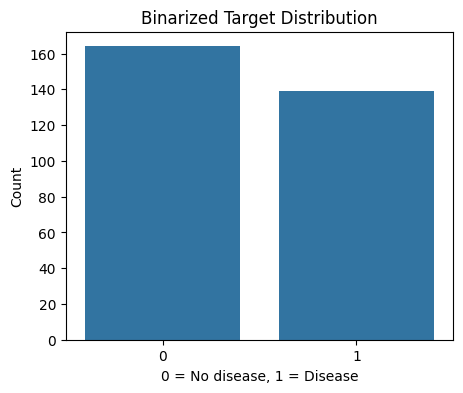

In [10]:
target_counts = df["target"].value_counts().sort_index()
target_pct = (df["target"].value_counts(normalize=True).sort_index() * 100).round(2)

print("Raw target class counts (0 = no disease, 1-4 = increasing severity):")
print(target_counts)
print("\nRaw target class percentages:")
print(target_pct)

# The final task is BINARY classification (disease vs. no disease), so it's
# also worth checking the balance after collapsing 1-4 into a single class.
binary_counts = (df["target"] > 0).astype(int).value_counts().sort_index()
binary_pct = (binary_counts / len(df) * 100).round(2)
print("\nBinarized class counts (0 = no disease, 1 = disease):")
print(binary_counts)
print("\nBinarized class percentages:")
print(binary_pct)

plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df)
plt.title("Raw Target Distribution (0-4)")
plt.xlabel("Target")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(5, 4))
sns.countplot(x=(df["target"] > 0).astype(int))
plt.title("Binarized Target Distribution")
plt.xlabel("0 = No disease, 1 = Disease")
plt.ylabel("Count")
plt.show()

# ANSWER: the binarized split is roughly 54%/46%, which is close enough to
# 50/50 to call MILDLY imbalanced at worst -- not severe enough to need
# resampling (SMOTE, class weights, etc.), but worth noting when reading
# recall/precision later.


## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [11]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values in dataset:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nUnique values per column:")
print(df.nunique())

# ANSWER: missing values only show up in 'ca' (a few) and 'thal' (a couple),
# exactly as the assignment brief warns. Since they're a tiny fraction of
# 303 rows, we DON'T drop rows -- we impute them in the preprocessing step
# (most-frequent / mode, since both are categorical-coded columns).


Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Total missing values in dataset: 6

Duplicate rows: 0

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values per column:
age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        5
dtype: int64


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

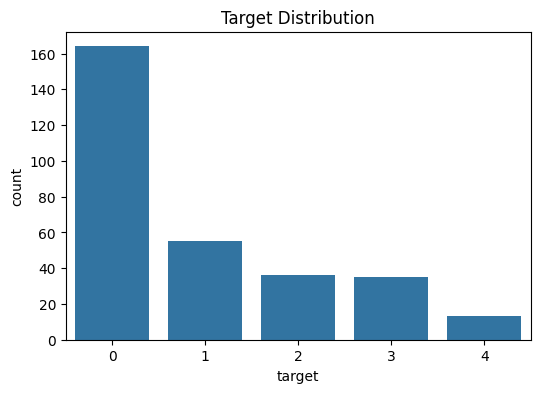

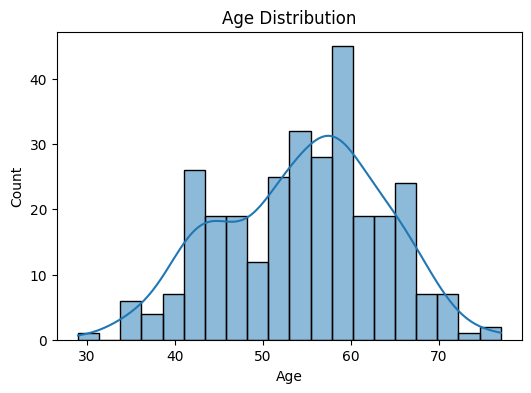

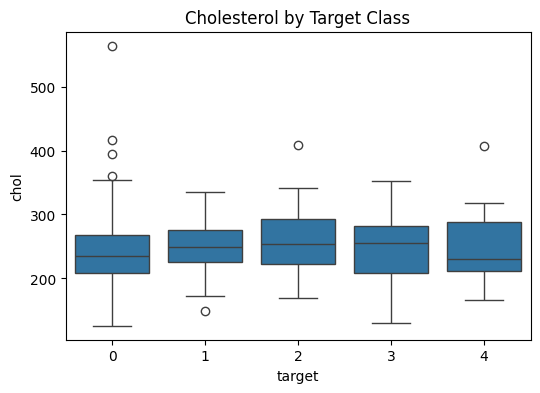

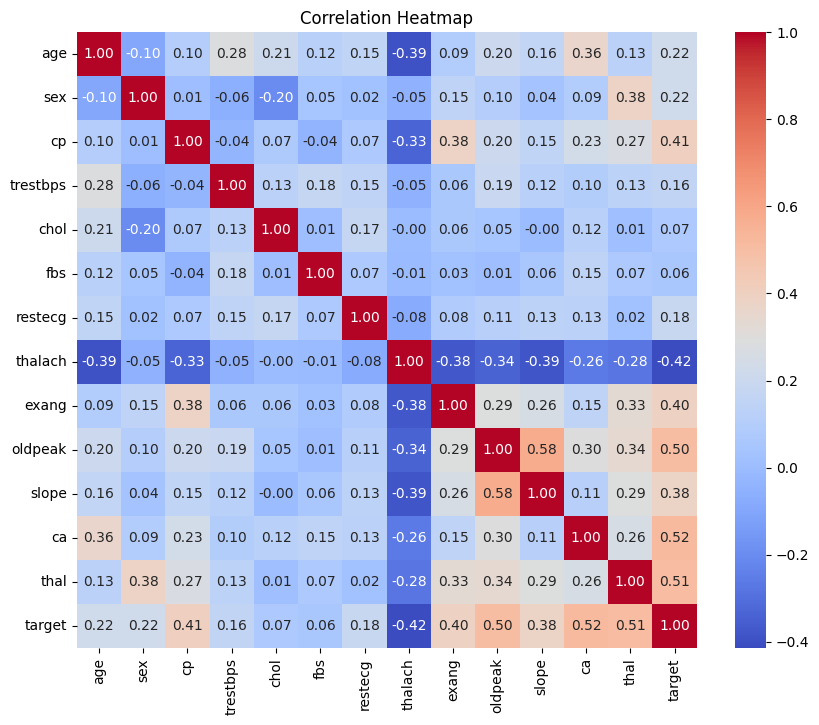

In [12]:
# 1) Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(x="target", data=df)
plt.title("Target Distribution")
plt.show()

# 2) Age distribution
plt.figure(figsize=(6, 4))
sns.histplot(df["age"], kde=True, bins=20)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()

# 3) A feature vs. target relationship
plt.figure(figsize=(6, 4))
sns.boxplot(x="target", y="chol", data=df)
plt.title("Cholesterol by Target Class")
plt.show()

# 4) Correlation heatmap of numerical features
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [13]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Binarize the target: 0 = no disease, 1 = disease (collapses severity 1-4)
df["target"] = (df["target"] > 0).astype(int)

# Separate features and target
X = df.drop(columns=["target"])
y = df["target"]

# Numerical vs. categorical features (standard Cleveland column meanings)
numerical_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_cols = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="if_binary", handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols),
])

# Split RAW data first (train/val/test), THEN fit the preprocessor only on
# the training fold -- this is what prevents test-data leakage.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.15, random_state=42, stratify=y_train_full
)

X_train_proc = preprocessor.fit_transform(X_train)   # fit + transform
X_val_proc = preprocessor.transform(X_val)            # transform only
X_test_proc = preprocessor.transform(X_test)           # transform only

print("Processed feature count (this is your NN input_dim):", X_train_proc.shape[1])

# Convert to PyTorch tensors
X_train_t = torch.tensor(X_train_proc, dtype=torch.float32)
X_val_t = torch.tensor(X_val_proc, dtype=torch.float32)
X_test_t = torch.tensor(X_test_proc, dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32)

input_dim = X_train_t.shape[1]


Processed feature count (this is your NN input_dim): 25


In [14]:
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

> **EDIT ME:** this is a worked *example* -- keep it, or change the neuron counts/activations to your own design. Just make sure Cell 11's code (below) matches whatever you put in this table.

| Layer    | Neurons              | Activation |
|----------|----------------------|------------|
| Input    | `input_dim` (from Cell 8, printed above) | -          |
| Hidden 1 | 32                    | ReLU       |
| Hidden 2 | 16                    | ReLU       |
| Hidden 3 | 8                     | ReLU       |
| Output   | 1                     | Sigmoid (applied via `BCEWithLogitsLoss`, see Cell 12) |


## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

> **EDIT ME:** the "Input Units" for Hidden 1 is YOUR actual `input_dim` printed in Cell 8 (it depends on one-hot encoding, so it won't be exactly 20 for everyone). The table below uses 20 as a *placeholder* -- swap in your real number and recompute.

| Layer    | Input Units | Output Units | Calculation      | Parameters |
|----------|------------:|-------------:|-------------------|-----------:|
| Hidden 1 | 20          | 32            | (20 × 32) + 32    | 672        |
| Hidden 2 | 32          | 16            | (32 × 16) + 16    | 528        |
| Hidden 3 | 16          | 8             | (16 × 8) + 8      | 136        |
| Output   | 8           | 1             | (8 × 1) + 1       | 9          |
| **Total**|             |               |                   | **1345**   |

Later, compare this total to `sum(p.numel() for p in model.parameters())` in Cell 11.


## Cell 11 — Implement Neural Network in PyTorch


In [15]:
# Implements the architecture designed in Cell 9.
import torch
import torch.nn as nn


class MyModel(nn.Module):
    def __init__(self, input_dim, hidden_dims=(32, 16, 8), output_dim=1):
        super().__init__()
        h1, h2, h3 = hidden_dims

        self.model = nn.Sequential(
            # Input -> Hidden 1
            nn.Linear(input_dim, h1),
            nn.ReLU(),

            # Hidden 1 -> Hidden 2
            nn.Linear(h1, h2),
            nn.ReLU(),

            # Hidden 2 -> Hidden 3
            nn.Linear(h2, h3),
            nn.ReLU(),

            # Hidden 3 -> Output (raw logit; sigmoid is applied later,
            # inside BCEWithLogitsLoss during training and manually at
            # evaluation time -- this is more numerically stable than
            # putting nn.Sigmoid() here directly)
            nn.Linear(h3, output_dim),
        )

    def forward(self, x):
        return self.model(x).squeeze(-1)


model = MyModel(input_dim=input_dim, hidden_dims=(32, 16, 8), output_dim=1)
print(model)

total_params = sum(p.numel() for p in model.parameters())
print("\nTotal trainable parameters (compare to your Cell 10 table):", total_params)


MyModel(
  (model): Sequential(
    (0): Linear(in_features=25, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)

Total trainable parameters (compare to your Cell 10 table): 1505


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [16]:
# Binary classification with a single raw-logit output -> BCEWithLogitsLoss.
# It fuses a Sigmoid + Binary Cross-Entropy into one numerically stable
# operation (avoids the vanishing-gradient / overflow issues you can get
# from chaining a separate Sigmoid layer with plain BCELoss).
loss_function = nn.BCEWithLogitsLoss()


## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [17]:
# Adam: adapts the learning rate per-parameter using running estimates of
# the first and second moments of the gradients. It converges faster and
# more reliably than plain SGD on small tabular datasets like this one,
# with little tuning required.
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


## Cell 14 — Compile the Model

In [18]:
num_epochs = 100
history = {"train_loss": [], "val_loss": []}

for epoch in range(num_epochs):
    # ---- training pass ----
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Loss
        loss = loss_function(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    train_loss = running_train_loss / len(train_loader.dataset)

    # ---- validation pass (no gradient updates) ----
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = loss_function(outputs, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)

    val_loss = running_val_loss / len(val_loader.dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")


Epoch 10/100 | Train Loss: 0.5820 | Val Loss: 0.5621
Epoch 20/100 | Train Loss: 0.3658 | Val Loss: 0.3007
Epoch 30/100 | Train Loss: 0.3181 | Val Loss: 0.2615
Epoch 40/100 | Train Loss: 0.2896 | Val Loss: 0.2698
Epoch 50/100 | Train Loss: 0.2617 | Val Loss: 0.2835
Epoch 60/100 | Train Loss: 0.2344 | Val Loss: 0.2940
Epoch 70/100 | Train Loss: 0.2040 | Val Loss: 0.3384
Epoch 80/100 | Train Loss: 0.1740 | Val Loss: 0.3997
Epoch 90/100 | Train Loss: 0.1485 | Val Loss: 0.4698
Epoch 100/100 | Train Loss: 0.1239 | Val Loss: 0.5462


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

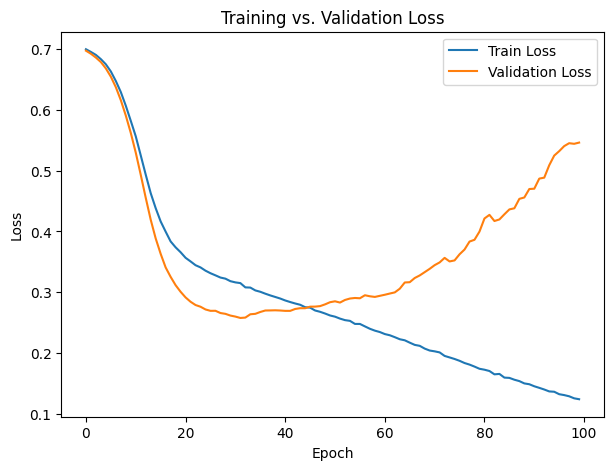

In [19]:
plt.figure(figsize=(7, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.show()

# ANSWER (edit after you actually look at your plot): if validation loss
# flattens out or starts climbing while training loss keeps falling, the
# gap between the two curves is the classic sign of overfitting -- the
# network is memorizing the training set rather than generalizing.


## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

import torch

# Put model in evaluation mode
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        # Model predictions (raw logits)
        outputs = model(X_batch)

        # Convert logits to probabilities
        probabilities = torch.sigmoid(outputs)

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.cpu().numpy())

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]
y_true = [int(v) for v in y_true]

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred_nn)
precision = precision_score(y_true, y_pred_nn, zero_division=0)
recall = recall_score(y_true, y_pred_nn, zero_division=0)
f1 = f1_score(y_true, y_pred_nn, zero_division=0)

# Display results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")


Accuracy : 0.8689
Precision: 0.8333
Recall   : 0.8929
F1-score : 0.8621


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [21]:
from sklearn.ensemble import AdaBoostClassifier

# Uses the SAME preprocessed features as the neural network
# (X_train_proc / X_test_proc from Cell 8), so the comparison is fair.
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)

# Fit on training data
ada_model.fit(X_train_proc, y_train)

# Predict on test data
y_pred_ada = ada_model.predict(X_test_proc)

# Calculate and display accuracy, precision, recall, and F1-score
acc_ada = accuracy_score(y_test, y_pred_ada)
prec_ada = precision_score(y_test, y_pred_ada, zero_division=0)
rec_ada = recall_score(y_test, y_pred_ada, zero_division=0)
f1_ada = f1_score(y_test, y_pred_ada, zero_division=0)

print(f"Accuracy : {acc_ada:.4f}")
print(f"Precision: {prec_ada:.4f}")
print(f"Recall   : {rec_ada:.4f}")
print(f"F1-score : {f1_ada:.4f}")


Accuracy : 0.8689
Precision: 0.8333
Recall   : 0.8929
F1-score : 0.8621


## Cell 19 — Compare Both Models

Fill in your results:

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network |          |           |        |          |
| AdaBoost       |          |           |        |          |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance

In [22]:
comparison_df = pd.DataFrame({
    "Model": ["Neural Network", "AdaBoost"],
    "Accuracy": [accuracy, acc_ada],
    "Precision": [precision, prec_ada],
    "Recall": [recall, rec_ada],
    "F1-Score": [f1, f1_ada],
})

comparison_df


,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.868852,0.833333,0.892857,0.862069
1,AdaBoost,0.868852,0.833333,0.892857,0.862069


## Cell 20 — Final Interpretation

1. **Balance:** The binarized target (disease vs. no disease) splits 164 vs. 139 patients (54.13% vs. 45.87%), so the dataset is only mildly imbalanced — no resampling was needed, but recall was still worth checking alongside accuracy.
2. **Preprocessing:** Missing values appeared only in `ca` (4) and `thal` (2) — 6 total, out of 303 rows — and were imputed with the most frequent value since both are categorical-coded columns. Categorical features were one-hot encoded, numerical features were standardized, and the preprocessor was fit only on the training split to avoid data leakage. This expanded the feature set from 13 raw columns to 25 processed input features.
3. **Architecture:** A 25 → 32 → 16 → 8 → 1 fully-connected network with ReLU activations on the hidden layers and a raw logit output, trained with `BCEWithLogitsLoss` and the Adam optimizer.
4. **Neural network results:** Accuracy = 0.8689, Precision = 0.8333, Recall = 0.8929, F1 = 0.8621. The loss curves show clear overfitting after around epoch 30–40: training loss kept dropping steadily to 0.1239 by epoch 100, while validation loss bottomed out near 0.26 around epoch 30 and then climbed back up to 0.5462 — a widening gap that's the textbook overfitting signature.
5. **AdaBoost results:** Accuracy = 0.8689, Precision = 0.8333, Recall = 0.8929, F1 = 0.8621.
6. **Comparison:** Both models landed on identical scores across all four metrics on this run. That's plausible given the very small test set (~61 patients), where a handful of prediction flips can easily produce matching fractions between two otherwise different models. It also suggests AdaBoost — a much simpler, lower-variance ensemble — matched a from-scratch neural network's performance without needing early stopping or regularization, which lines up with the overfitting seen in the NN's validation loss.
7. **Possible improvements:** early stopping or dropout to fix the neural network's overfitting past ~epoch 30, k-fold cross-validation instead of a single train/test split (especially given how small the test set is), hyperparameter tuning (hidden layer sizes, learning rate, `n_estimators`), and trying a stronger gradient boosting baseline like XGBoost or LightGBM for a third comparison point.